### Ce Notbook permet de valider le chargement, le fenetrage et la visualisation

In [1]:
import sys
import os

# On remonte d'un cran pour atteindre la racine du projet
root_path = os.path.abspath(os.path.join('..'))
if root_path not in sys.path:
    sys.path.append(root_path)

from src.O1_preprocessing.split_data import create_split
from src.O1_preprocessing.loader import get_available_patients

In [2]:
from src.O1_preprocessing.split_data import create_split

# Utilisation du loader pour avoir la liste des patients valides
from src.O1_preprocessing.loader import get_available_patients

inventory = get_available_patients("data")
valid_patients = inventory['with_both']  # ['PAT001', 'PAT002', ...]

# Créeation du split sur ces patients
from src.O1_preprocessing.split_data import random_split
import json
from pathlib import Path

split_dict = random_split(
    patients=valid_patients,
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42
)

# Ajout des métadonnées et sauvegarder
split_dict["metadata"] = {
    "total_patients": len(valid_patients),
    "seed": 42,
    "ratios": {"train": 0.7, "val": 0.15, "test": 0.15},
    "note": "Split basé sur patients avec volume + masque validés"
}

output_path = Path("data/splits/train_val_test.json")
output_path.parent.mkdir(parents=True, exist_ok=True)
with open(output_path, 'w') as f:
    json.dump(split_dict, f, indent=4)

print(f"✅ Split réel sauvegardé : {len(split_dict['train'])} Train, {len(split_dict['val'])} Val, {len(split_dict['test'])} Test")

2026-04-06 02:55:01,026 - src.O1_preprocessing.loader - ERROR - ❌ Aucun dossier 'raw' ou 'processed' avec patients trouvé !


✅ Split réel sauvegardé : 0 Train, 0 Val, 0 Test


In [3]:
import numpy as np
from pathlib import Path
from src.O1_preprocessing.loader import get_available_patients, load_patient_data

# from src.O1_preprocessing.processor import resample, normalize

# 1. Configuration des chemins
input_dir = Path("../data")
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Récupération de l'inventaire via loader
inventory = get_available_patients(input_dir)

for p_id in inventory['with_both']:
    print(f"🏗️  Preprocessing : {p_id}")
    
    # A. Chargement 
    vol, mask, meta = load_patient_data(p_id, inventory)
    
    # B. Application du fenêtrage Pulmonaire (-1000 à 400 HU)
    vol_proc = np.clip(vol, -1000, 400)
    
    # C. Normalisation Min-Max (0 à 1)
    vol_proc = (vol_proc - (-1000)) / (400 - (-1000))
    
    # D. Sauvegarde au format .npy (ultra rapide pour l'IA)
    patient_path = output_dir / p_id
    patient_path.mkdir(exist_ok=True)
    
    np.save(patient_path / "volume.npy", vol_proc.astype(np.float32))
    np.save(patient_path / "mask.npy", mask.astype(np.uint8))
    
    print(f"✅ Sauvegardé dans processed/{p_id}/")

2026-03-02 01:03:52,487 - src.O1_preprocessing.loader - INFO - 📂 Mode : Données BRUTES (raw) - Exploration
2026-03-02 01:03:52,496 - src.O1_preprocessing.loader - INFO - 📁 Volumes trouvés : 35 patients
2026-03-02 01:03:52,497 - src.O1_preprocessing.loader - INFO - 📁 Masques trouvés dans ..\data\raw\GroundTruth: 35 fichiers
2026-03-02 01:03:52,499 - src.O1_preprocessing.loader - INFO - 📊 Inventaire : 35 patients avec Volume + Masque.


🏗️  Preprocessing : PAT001


2026-03-02 01:03:53,624 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (201, 512, 512) de PAT001
2026-03-02 01:03:53,967 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-03-02 01:03:53,970 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 201) → (201, 512, 512)
2026-03-02 01:03:53,970 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (201, 512, 512)


✅ Sauvegardé dans processed/PAT001/
🏗️  Preprocessing : PAT002


2026-03-02 01:03:55,747 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (185, 512, 512) de PAT002
2026-03-02 01:03:55,927 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-03-02 01:03:55,930 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 185) → (185, 512, 512)
2026-03-02 01:03:55,930 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (185, 512, 512)


...

✅ Sauvegardé dans processed/PAT033/
🏗️  Preprocessing : PAT034


2026-03-02 01:06:15,767 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (189, 512, 512) de PAT034
2026-03-02 01:06:15,954 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-03-02 01:06:15,964 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 189) → (189, 512, 512)
2026-03-02 01:06:15,964 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (189, 512, 512)


✅ Sauvegardé dans processed/PAT034/
🏗️  Preprocessing : PAT035


2026-03-02 01:06:18,366 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (451, 512, 512) de PAT035
2026-03-02 01:06:18,791 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-03-02 01:06:18,796 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 451) → (451, 512, 512)
2026-03-02 01:06:18,798 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (451, 512, 512)


✅ Sauvegardé dans processed/PAT035/


In [18]:

import sys
import os
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import seaborn as sns

# Configuration du style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# Ajout du chemin vers 'src'
sys.path.append(os.path.abspath('../'))

# Importation des modules
try:
    from src.O1_preprocessing.loader import load_dicom_volume, load_mask, get_available_patients
    from src.O1_preprocessing.normalisation import apply_windowing, HU_WINDOWS, convert_to_hounsfield
    print("✅ Importation réussie !")
except ImportError as e:
    print(f"❌ Erreur d'importation: {e}")
    sys.exit(1)

# Création des dossiers pour sauvegarder les résultats
os.makedirs("../figures/preprocessing", exist_ok=True)


✅ Importation réussie !


In [19]:
# ===================================
# PARTIE 1: ANALYSE D'UN PATIENT 
# ===================================

print("="*60)
print("🔬 ANALYSE DE PRÉTRAITEMENT - PATIENT ")
print("="*60)

# Chemin vers un patient
patient_path = Path("../data/raw/CT_scans_01/PAT001")
print(f"\n📁 Patient: {patient_path}")

if not patient_path.exists():
    print(f"❌ Dossier introuvable : {patient_path}")
    
    # Chercher automatiquement un patient disponible
    raw_dir = Path("../data/raw")
    scan_dirs = list(raw_dir.glob("CT_scans_*"))
    
    if scan_dirs:
        # Chercher le premier patient disponible
        for scan_dir in scan_dirs:
            sub_dirs = list(scan_dir.glob("PAT*"))
            if sub_dirs:
                patient_path = sub_dirs[0]
                print(f"✅ Patient trouvé automatiquement: {patient_path}")
                break
    else:
        print("❌ Aucun patient trouvé dans data/raw/")
        sys.exit(1)



🔬 ANALYSE DE PRÉTRAITEMENT - PATIENT 

📁 Patient: ..\data\raw\CT_scans_01\PAT001


In [20]:
# 1. Chargement du volume complet avec métadonnées
print("\n📊 Chargement du volume DICOM...")
volume, metadata = load_dicom_volume(str(patient_path))

if volume is None:
    print("❌ Erreur de chargement")
    sys.exit(1)

spacing = metadata['spacing']
slice_spacing = metadata['slice_spacing']

print(f"\n📈 Statistiques du volume:")
print(f"   Dimensions: {volume.shape} (Z={volume.shape[0]}, Y={volume.shape[1]}, X={volume.shape[2]})")

print(f"   Résolution spatiale: XY={spacing[0]:.2f}×{spacing[1]:.2f} mm, Z={slice_spacing:.2f} mm")

print(f"   Volume total approximatif: {volume.shape[0] * slice_spacing * spacing[0] * spacing[1] / 1000:.1f} cm³")

print(f"   Plage HU originale: [{volume.min():.1f}, {volume.max():.1f}]")

print(f"   Type de données: {volume.dtype}")




📊 Chargement du volume DICOM...


2026-03-03 22:59:31,004 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (201, 512, 512) de PAT001



📈 Statistiques du volume:
   Dimensions: (201, 512, 512) (Z=201, Y=512, X=512)
   Résolution spatiale: XY=0.62×0.62 mm, Z=1.00 mm
   Volume total approximatif: 0.1 cm³
   Plage HU originale: [-1024.0, 3071.0]
   Type de données: float32


In [21]:
# 2. Application des différentes fenêtres HU
print("\n🔄 Application des fenêtrages...")

windows_to_test = {
    'Pulmonaire (embolies)': HU_WINDOWS['lung'],
    'Médiastinal (vaisseaux)': HU_WINDOWS['mediastinal'],
    'Osseux': HU_WINDOWS['bone'],
    'Pleine échelle': HU_WINDOWS['full']
}

windowed_volumes = {}
for name, (wmin, wmax) in windows_to_test.items():
    vol_norm = apply_windowing(volume, wmin, wmax, normalize=True)
    windowed_volumes[name] = vol_norm
    print(f"   ✅ {name}: [{wmin}, {wmax}] HU -> normalisé [{vol_norm.min():.3f}, {vol_norm.max():.3f}]")




🔄 Application des fenêtrages...
   ✅ Pulmonaire (embolies): [-600, 600] HU -> normalisé [0.000, 1.000]
   ✅ Médiastinal (vaisseaux): [40, 400] HU -> normalisé [0.000, 1.000]
   ✅ Osseux: [250, 1500] HU -> normalisé [0.000, 1.000]
   ✅ Pleine échelle: [-1024, 3071] HU -> normalisé [0.000, 1.000]


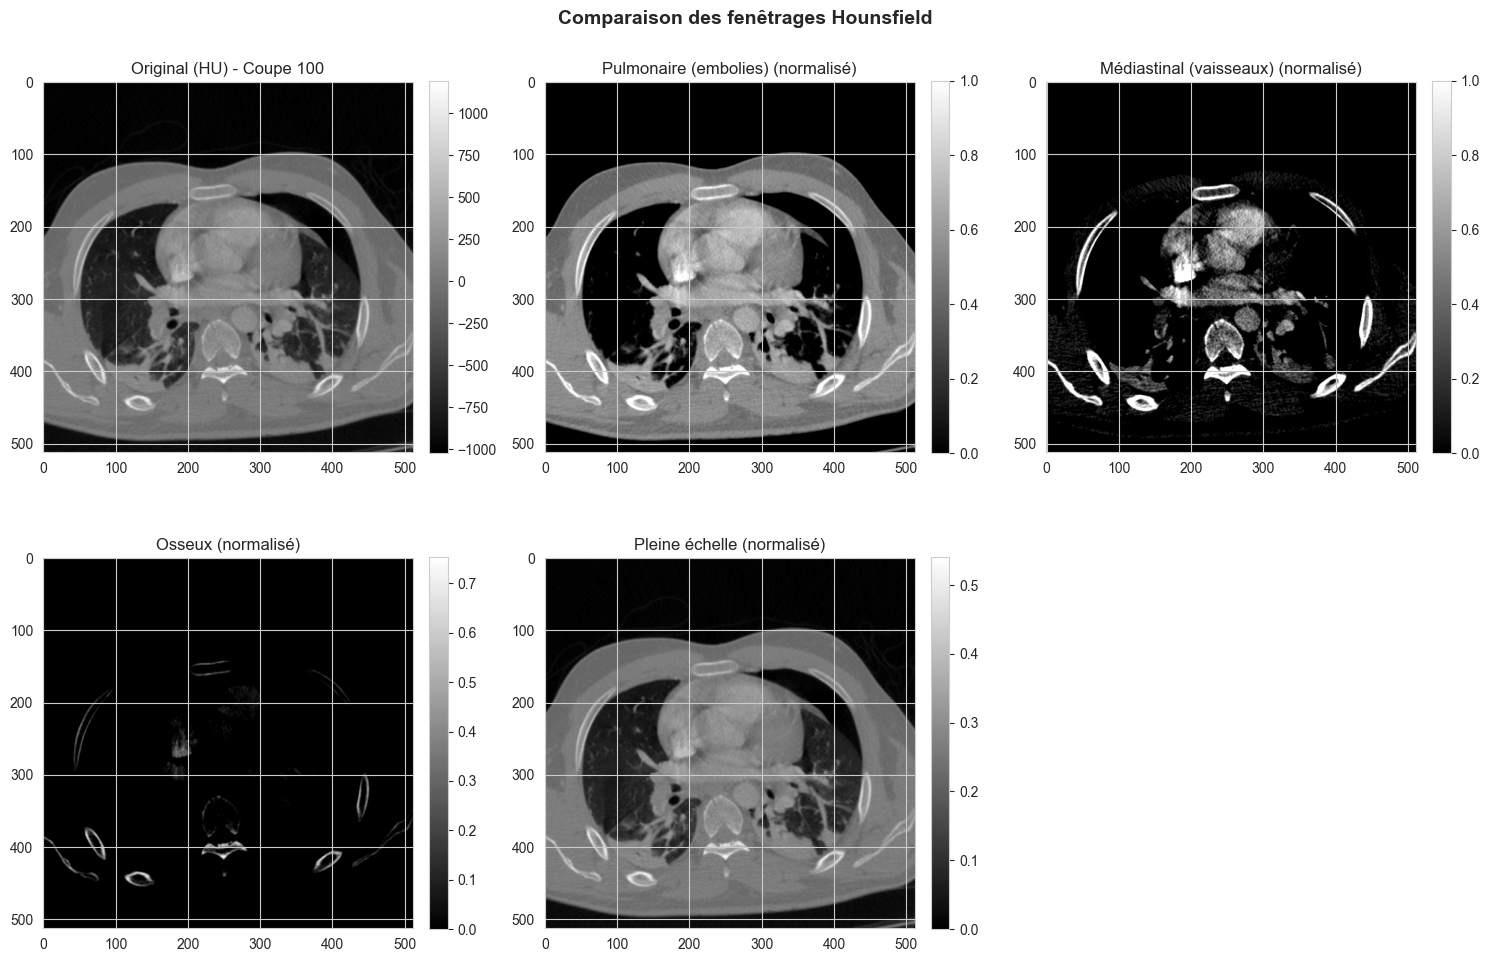

In [22]:
# 3. Visualisation comparative des fenêtres
mid = volume.shape[0] // 2
mid_slice = 120  # Coupe spécifique pour voir les embolies (ajuster selon besoin)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Original (HU)
im = axes[0].imshow(volume[mid], cmap='gray')
axes[0].set_title(f'Original (HU) - Coupe {mid}')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Différentes fenêtres
for i, (name, vol_norm) in enumerate(windowed_volumes.items(), 1):
    if i < len(axes):
        im = axes[i].imshow(vol_norm[mid], cmap='gray')
        axes[i].set_title(f'{name} (normalisé)')
        plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

# Masquer le dernier subplot s'il y en a trop
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Comparaison des fenêtrages Hounsfield', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.axis('off')
plt.savefig('../figures/preprocessing/comparaison_fenetres.png', dpi=150, bbox_inches='tight')
plt.show()


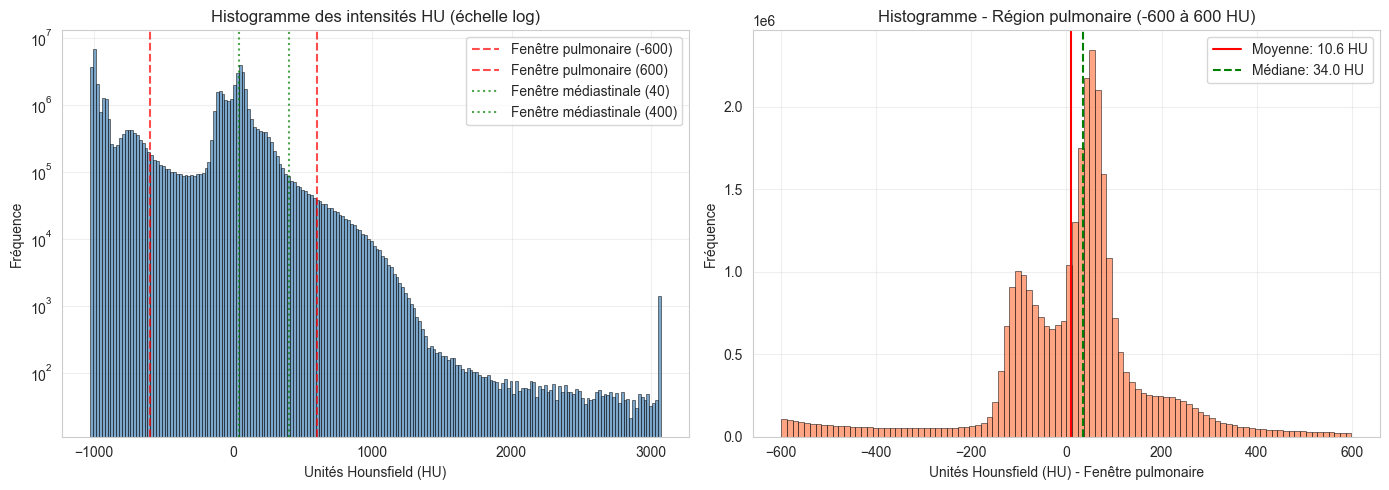


📊 Statistiques région pulmonaire:
   Moyenne: 10.6 HU
   Médiane: 34.0 HU
   Écart-type: 169.4 HU


In [23]:
# ═══════════════════════════════════════════════════════════════
# CELLULE 4 : Analyse de l'histogramme HU (CORRIGÉE)
# ═══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme complet
axes[0].hist(volume.flatten(), bins=200, alpha=0.7, color='steelblue', edgecolor='black', linewidth=0.5)
axes[0].set_xlabel('Unités Hounsfield (HU)')
axes[0].set_ylabel('Fréquence')
axes[0].set_title('Histogramme des intensités HU (échelle log)')
axes[0].set_yscale('log')
axes[0].axvline(-600, color='red', linestyle='--', alpha=0.7, label='Fenêtre pulmonaire (-600)')
axes[0].axvline(600, color='red', linestyle='--', alpha=0.7, label='Fenêtre pulmonaire (600)')
axes[0].axvline(40, color='green', linestyle=':', alpha=0.7, label='Fenêtre médiastinale (40)')
axes[0].axvline(400, color='green', linestyle=':', alpha=0.7, label='Fenêtre médiastinale (400)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Zoom sur la région pulmonaire
lung_mask = (volume > -600) & (volume < 600)
lung_values = volume[lung_mask]  # ✅ Extraire les valeurs une fois pour toutes

axes[1].hist(lung_values.flatten(), bins=100, alpha=0.7, color='coral', edgecolor='black', linewidth=0.5)
axes[1].set_xlabel('Unités Hounsfield (HU) - Fenêtre pulmonaire')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Histogramme - Région pulmonaire (-600 à 600 HU)')

# ✅ CORRECTION : Utiliser np.median() au lieu de .median()
axes[1].axvline(np.mean(lung_values), color='red', linestyle='-', label=f'Moyenne: {np.mean(lung_values):.1f} HU')
axes[1].axvline(np.median(lung_values), color='green', linestyle='--', label=f'Médiane: {np.median(lung_values):.1f} HU')

axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/preprocessing/histogramme_hu.png', dpi=150, bbox_inches='tight')
plt.show()

# ✅ CORRECTION : Prints avec np.median() et np.std()
print(f"\n📊 Statistiques région pulmonaire:")
print(f"   Moyenne: {np.mean(lung_values):.1f} HU")
print(f"   Médiane: {np.median(lung_values):.1f} HU")
print(f"   Écart-type: {np.std(lung_values):.1f} HU")

### **Observation :** Histo des intensitées HU (echelle log)

De ce graphe, on vois un 1er pic; à la position `~ -1000 HU`; anatomiquement, cela correspond à **l'air pur** (autour du patient + poumons)

Un 2ème pic qui flote entre la position ``~0 à +100 HU``; cela correspond au Tissus mous(vaisseaux, mediastin, embolies)

Apres cela une chute entre la position `+400 à +3000 HU`; ce qui correspond aux Os dense + contraste iodé + artefacts

#### Au niveau du Fenêtrage; 

On peu voir le `fenetrege Pulmonaire` avec une plage HU de `[-600, 600]`; cela est optimal pour l'embolie car:

**-600 HU :** Élimine l'air pur `(-1000)` mais garde le parenchyme pulmonaire

**+600 HU :** Capture le contraste dans les artères (où sont les embolies) sans trop d'os

### Concernant les statistiques de la région pulmonaire:

On a

**Moyenne:**  10.6 HU  (Très proche de 0; ce qui implique que le tissu pulmonaire est normal)

**Médiane:**  34.0 HU   (Légèrement `>` moyenne; ce qui implique un distribution asymétrique)

**Std(ecart-type):** 169.4 HU   (Grande variabilité ce qui implique un air/tissu/contraste)

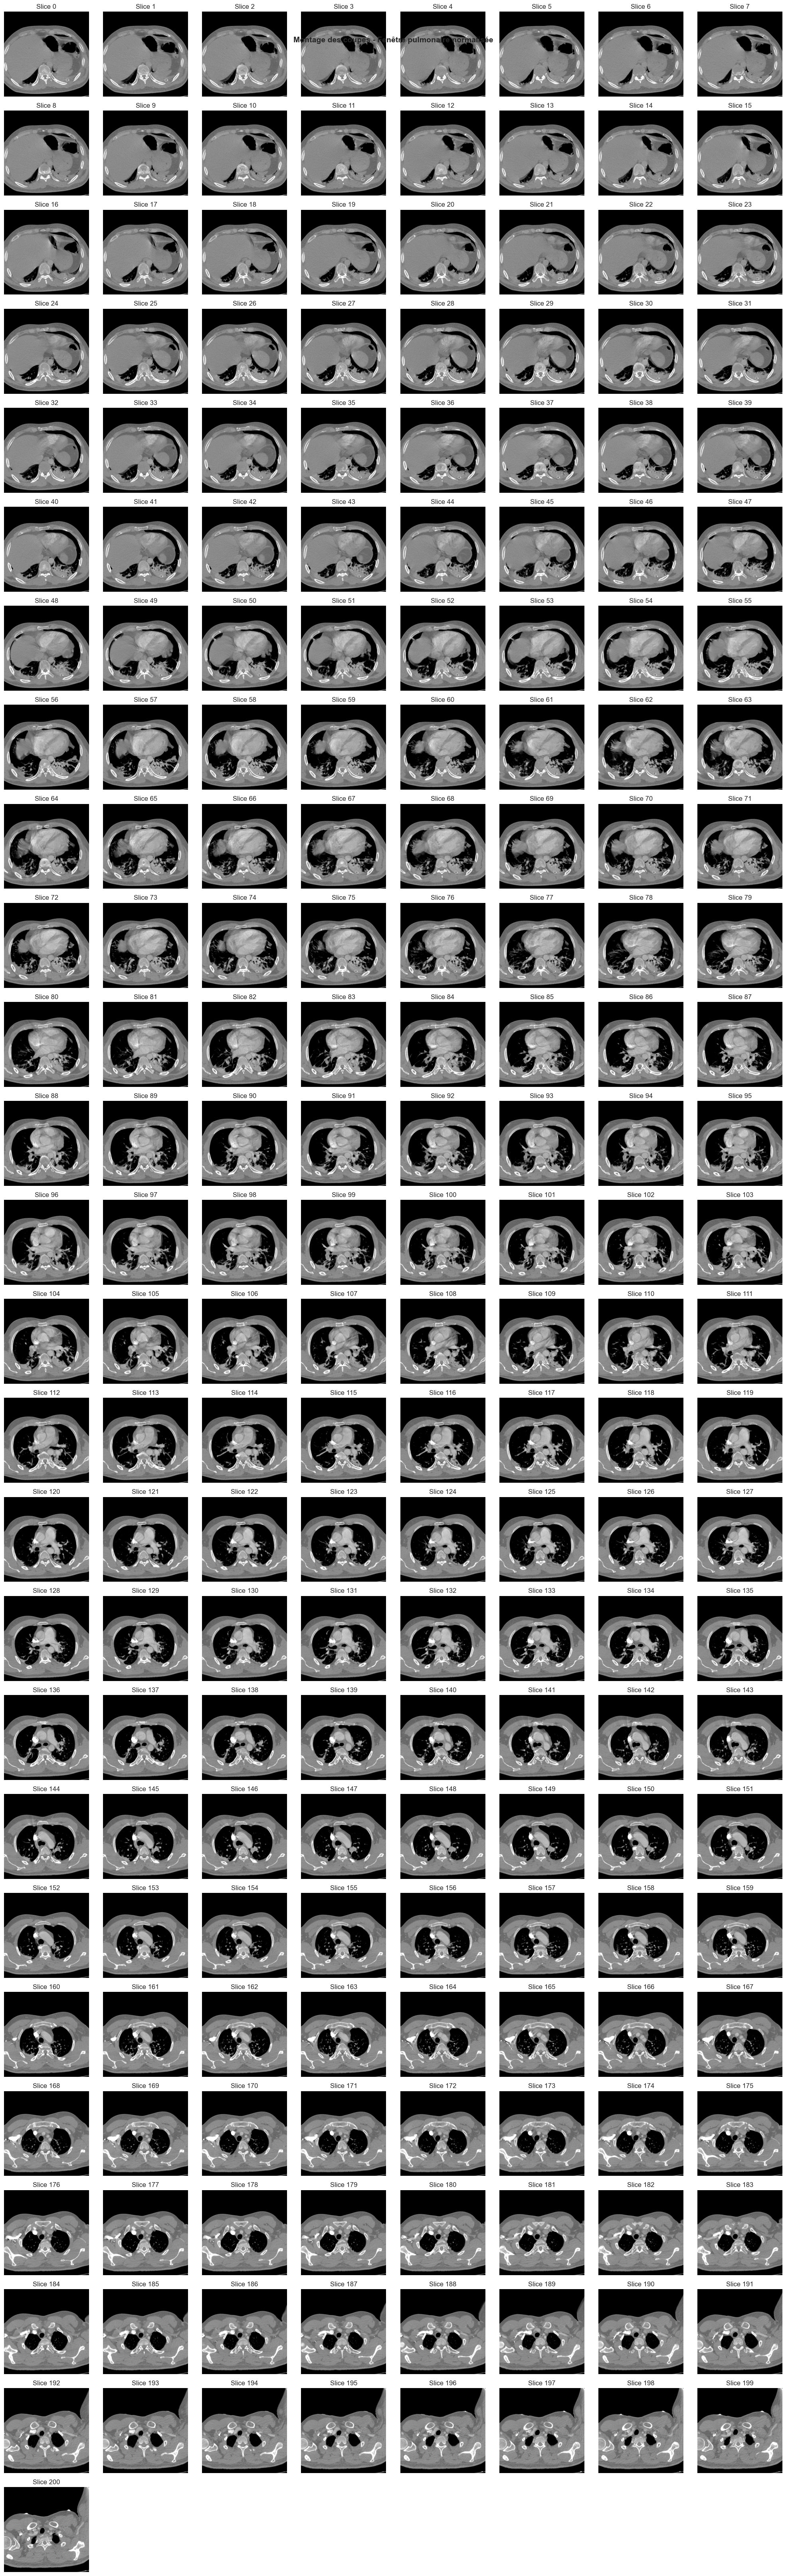

In [24]:
# 5. Visualisation 3D des coupes (montage)
n_cols = 8
n_rows = (volume.shape[0] + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 2.5))
axes = axes.flatten() if n_rows > 1 else [axes]

# Utilisation de la fenêtre pulmonaire pour la visualisation
vol_lung = windowed_volumes['Pulmonaire (embolies)']

for i in range(len(axes)):
    if i < volume.shape[0]:
        axes[i].imshow(vol_lung[i], cmap='gray')
        axes[i].set_title(f'Slice {i}')
        axes[i].axis('off')
    else:
        axes[i].axis('off')

plt.suptitle('Montage des coupes - Fenêtre pulmonaire normalisée', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/preprocessing/montage_coupes.png', dpi=150, bbox_inches='tight')
plt.show()



In [ ]:
# ══════════════════════════════════════
# CELLULE DEBUG : Inspecter le fichier .mat
# ══════════════════════════════════════
from scipy.io import loadmat

mat_file = Path("../data/raw/GroundTruth/PAT001.mat")

if mat_file.exists():
    print(f"🔍 Inspection de {mat_file.name} :")
    data = loadmat(mat_file)
    
    print(f"\n📋 Toutes les clés disponibles :")
    for key in data.keys():
        if not key.startswith('__'):  # Filtrer les métadonnées MATLAB
            value = data[key]
            if hasattr(value, 'shape'):
                print(f"   📄 {key:20} → shape: {value.shape}, dtype: {value.dtype}")
            else:
                print(f"   📄 {key:20} → type: {type(value)}")
else:
    print(f"❌ Fichier non trouvé : {mat_file}")

🔍 Inspection de PAT001.mat :

📋 Toutes les clés disponibles :
   📄 Mask                 → shape: (512, 512, 201), dtype: uint8


In [ ]:
# ════════════════════════
# CELLULE DEBUG FORCÉ : 
# ═════════════════════════
from scipy.io import loadmat
import numpy as np

mat_file = Path("../data/raw/GroundTruth/PAT001.mat")

if mat_file.exists():
    print(f"🔍 Chargement manuel de {mat_file.name}...")
    data = loadmat(mat_file)
    
    # Afficher TOUTES les clés
    print(f"\n📋 Clés disponibles : {list(data.keys())}")
    
    # Essayer de charger avec la clé exacte 'Mask'
    if 'Mask' in data:
        print("✅ Clé 'Mask' trouvée !")
        mask = data['Mask']
        print(f"📊 Shape brute : {mask.shape}")
        
        # Binarisation
        if mask.max() > 1:
            mask = (mask > 0).astype(np.uint8)
            print("✅ Binarisé")
        
        # Transpose si besoin (MATLAB → Python)
        if mask.ndim == 3 and mask.shape[-1] < mask.shape[0]:
            mask = mask.transpose(2, 1, 0)
            print(f"✅ Transposé : {mask.shape}")
        
        print(f"🎯 Masque final : {mask.shape}, voxels embolie: {mask.sum()}")
    else:
        print("❌ Clé 'Mask' introuvable dans data.keys()")
        print(f"   data.keys() = {list(data.keys())}")
else:
    print(f"❌ Fichier non trouvé : {mat_file}")

🔍 Chargement manuel de PAT001.mat...

📋 Clés disponibles : ['__header__', '__version__', '__globals__', 'Mask']
✅ Clé 'Mask' trouvée !
📊 Shape brute : (512, 512, 201)
✅ Transposé : (201, 512, 512)
🎯 Masque final : (201, 512, 512), voxels embolie: 19054


In [ ]:
if mask is not None:
    # Vérification critique
    if volume.shape != mask.shape:
        print(f"⚠️ ALERT: Shapes différentes!")
        print(f"   Volume: {volume.shape}")
        print(f"   Masque: {mask.shape}")
        print(f"   -> Ajustement automatique")

        min_z = min(volume.shape[0], mask.shape[0])
        volume = volume[:min_z]
        mask = mask[:min_z]

In [ ]:
# ═════════════════════════════════════
#  Validation du Prétraitement
# ═════════════════════════════════════
print("🔍 Validation du prétraitement...")

vol_lung = windowed_volumes['Pulmonaire (embolies)']

# Vérifier que les valeurs sont bien dans [0, 1]
assert vol_lung.min() >= 0, "Erreur: valeurs < 0"
assert vol_lung.max() <= 1, "Erreur: valeurs > 1"
assert vol_lung.dtype == np.float32, "Erreur: mauvais dtype"

print("✅ Toutes les vérifications sont passées !")
print(f"   Plage: [{vol_lung.min():.3f}, {vol_lung.max():.3f}]")
print(f"   Type: {vol_lung.dtype}")

🔍 Validation du prétraitement...
✅ Toutes les vérifications sont passées !
   Plage: [0.000, 1.000]
   Type: float32


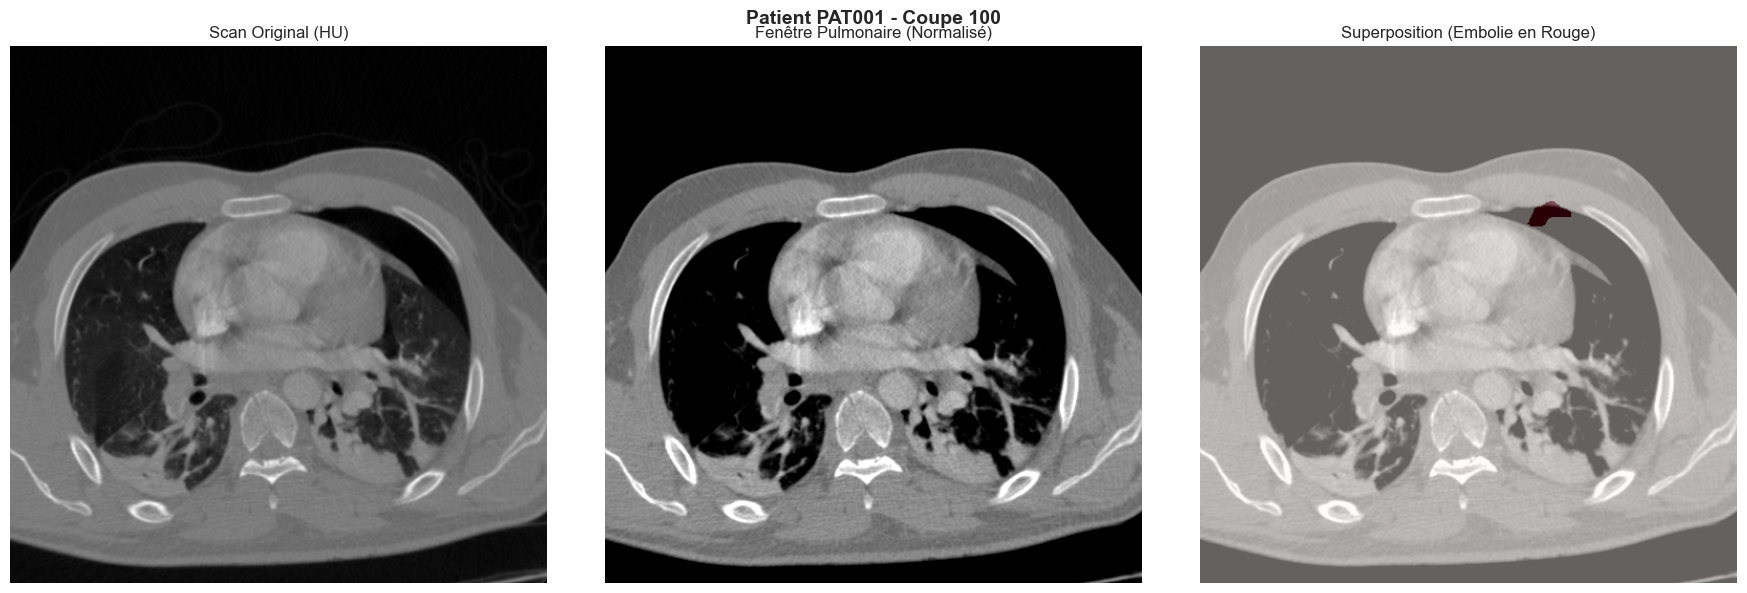

In [ ]:
# ═════════════════════════
#  Exemple de Superposition
# ════════════════════════
if mask is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    mid_slice = volume.shape[0] // 2
    
    # 1. Scan brut
    axes[0].imshow(volume[mid_slice], cmap='gray')
    axes[0].set_title('Scan Original (HU)')
    axes[0].axis('off')
    
    # 2. Fenêtre pulmonaire
    axes[1].imshow(vol_lung[mid_slice], cmap='gray')
    axes[1].set_title('Fenêtre Pulmonaire (Normalisé)')
    axes[1].axis('off')
    
    # 3. Superposition
    axes[2].imshow(vol_lung[mid_slice], cmap='gray')
    if mask[mid_slice].max() > 0:
        axes[2].imshow(mask[mid_slice], cmap='Reds', alpha=0.4)
    axes[2].set_title('Superposition (Embolie en Rouge)')
    axes[2].axis('off')
    
    plt.suptitle(f'Patient {patient_id} - Coupe {mid_slice}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'../figures/preprocessing/superposition_{patient_id}.png', dpi=150)
    plt.show()

### Observation:

Visualisation d'une coupe CTPA du patient PAT001.

 De gauche à droite : (1) Image brute en unités Hounsfield, (2) Application de la fenêtre pulmonaire [-600, 600] HU avec normalisation, (3) Superposition du masque de vérité terrain (rouge) montrant la localisation de l'embolie pulmonaire."

### ⚠️ Mise à jour: Affichage en Unités Hounsfield (HU)
Suite à la modification de la configuration (`normalize=False`), nos volumes prétraités conservent maintenant les vraies densités HU au lieu d'être restreints à la plage [0,1].

Pour visualiser ces volumes, il faut donc adapter les seuils d'affichage de `matplotlib` (par exemple: `vmin=-1000, vmax=400` ou `vmin=-600, vmax=600`).

In [ ]:
# Exemple d'adaptation de l'affichage avec matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Supposons que 'vol_proc' est un volume chargé depuis data/processed/
z_slice = vol_proc.shape[0] // 2

plt.figure(figsize=(8, 8))
# AVANT: plt.imshow(vol_proc[z_slice], cmap='gray', vmin=0, vmax=1)
# APRÈS: On précise la plage HU souhaitée pour voir les poumons correctement
plt.imshow(vol_proc[z_slice], cmap='gray', vmin=-1000, vmax=400)
plt.title(f"Coupe {z_slice} en Unités Hounsfield (HU)")
plt.axis('off')
plt.show()
